# Numerical results: European option pricing

This notebook collects the main results from the Black–Scholes and Monte Carlo implementations. It compares analytical prices with Monte Carlo estimates, then measures the effect of antithetic variates across repeated runs.

All experiments are reproducible through fixed random seeds. The Monte Carlo path budget counts total simulated terminal prices; with antithetic variates, those paths are arranged into $Z,-Z$ pairs.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
from european_option_pricing.black_scholes import black_scholes
from european_option_pricing.monte_carlo import monte_carlo_price

COLORS = {'call': '#2463A5', 'put': '#C4515C'}
METHOD_COLORS = {'Ordinary': '#2463A5', 'Antithetic': '#C4515C'}
INK = '#263445'
MUTED = '#64748B'
GRID = '#DCE3EA'
plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 10,
    'axes.titlesize': 12, 'axes.titleweight': 'bold',
    'axes.labelsize': 10, 'figure.titlesize': 15, 'figure.titleweight': 'bold',
    'axes.edgecolor': '#C8D1DC', 'axes.labelcolor': INK, 'text.color': INK,
    'xtick.color': MUTED, 'ytick.color': MUTED,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8, 'grid.alpha': 0.8,
    'legend.frameon': False, 'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'savefig.facecolor': 'white', 'lines.linewidth': 2,
})

## Benchmark and no-arbitrage checks

The benchmark is an at-the-money European call and put with one year to expiry. For a continuous dividend yield $q$, put–call parity is $C-P=Se^{-qT}-Ke^{-rT}$. The European price bounds use discounted spot and strike.

In [2]:
parameters = {
    'S': 100.0,
    'K': 100.0,
    'T': 1.0,
    'r': 0.05,
    'sigma': 0.20,
    'q': 0.0,
}
option_types = ['call', 'put']
analytical_prices = {
    kind: black_scholes(**parameters, option_type=kind)
    for kind in option_types
}
discounted_spot = parameters['S'] * np.exp(-parameters['q'] * parameters['T'])
discounted_strike = parameters['K'] * np.exp(-parameters['r'] * parameters['T'])
parity_value = discounted_spot - discounted_strike

print(f"Analytical call: {analytical_prices['call']:.6f}")
print(f"Analytical put:  {analytical_prices['put']:.6f}")
print(f"Put-call parity residual: {(analytical_prices['call'] - analytical_prices['put']) - parity_value:.3e}")
print(f"Call bounds: [{max(discounted_spot - discounted_strike, 0):.6f}, {discounted_spot:.6f}]")
print(f"Put bounds:  [{max(discounted_strike - discounted_spot, 0):.6f}, {discounted_strike:.6f}]")

Analytical call: 10.450584
Analytical put:  5.573526
Put-call parity residual: 0.000e+00
Call bounds: [4.877058, 100.000000]
Put bounds:  [0.000000, 95.122942]


## Analytical prices and Monte Carlo estimates

The plot compares 100,000-path estimates from ordinary and antithetic sampling with the analytical price. Error bars are 95% normal-approximation confidence intervals. Standard errors for antithetic estimates are calculated from pair-average payoffs, which are the independent observations.

In [3]:
n_paths = 100_000
confidence_level = 0.95
price_results = {}
for option_index, kind in enumerate(option_types):
    price_results[kind] = {}
    for method_index, (method, use_antithetic) in enumerate(
        [('Ordinary', False), ('Antithetic', True)]
    ):
        price_results[kind][method] = monte_carlo_price(
            **parameters,
            option_type=kind,
            n_paths=n_paths,
            confidence_level=confidence_level,
            rng=73021 + 100 * option_index + method_index,
            antithetic=use_antithetic,
        )

header = f"{'Option':<8} {'Method':<12} {'Estimate':>11} {'95% confidence interval':>29} {'Error':>10} {'SE':>10}"
print(header)
print('-' * len(header))
for kind in option_types:
    for method in ('Ordinary', 'Antithetic'):
        result = price_results[kind][method]
        error = result.price - analytical_prices[kind]
        interval = f"[{result.ci_lower:.5f}, {result.ci_upper:.5f}]"
        print(f"{kind.title():<8} {method:<12} {result.price:>11.5f} "
              f"{interval:>29} {error:>10.5f} {result.standard_error:>10.5f}")

Option   Method          Estimate       95% confidence interval      Error         SE
-------------------------------------------------------------------------------------
Call     Ordinary        10.40830          [10.31742, 10.49919]   -0.04228    0.04637
Call     Antithetic      10.47508          [10.41057, 10.53959]    0.02449    0.03291
Put      Ordinary         5.55199            [5.49856, 5.60542]   -0.02153    0.02726
Put      Antithetic       5.57839            [5.53729, 5.61950]    0.00487    0.02097


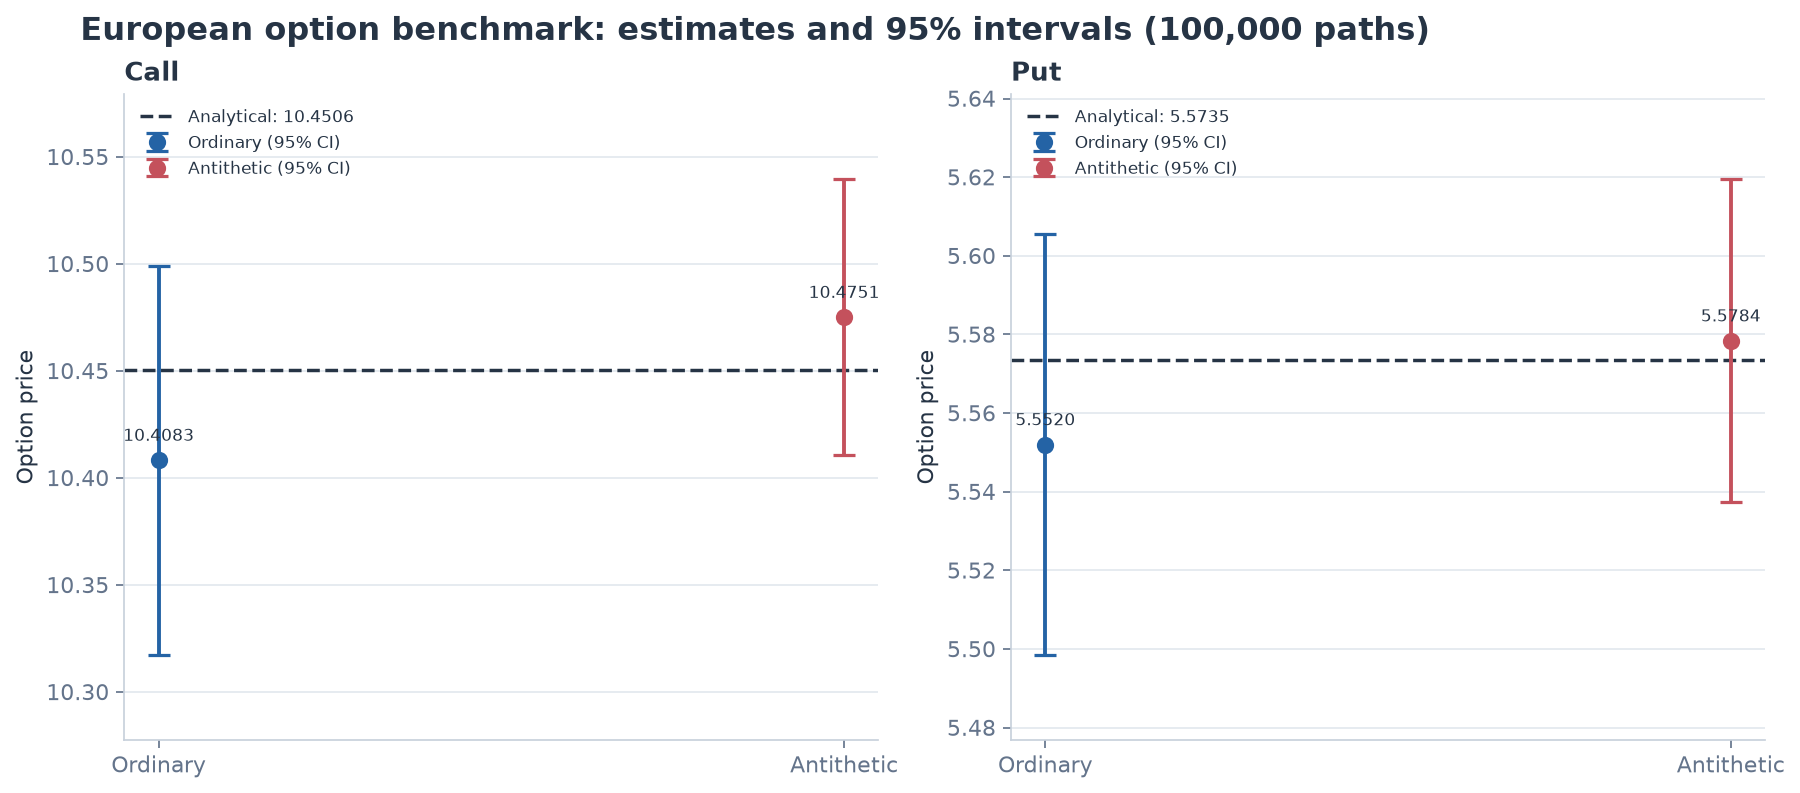

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 5.0), constrained_layout=True)
method_order = ('Ordinary', 'Antithetic')
x_positions = {'Ordinary': 0, 'Antithetic': 1}
for ax, kind in zip(axes, option_types):
    analytic = analytical_prices[kind]
    for method in method_order:
        x = x_positions[method]
        result = price_results[kind][method]
        color = METHOD_COLORS[method]
        ax.errorbar(
            x, result.price,
            yerr=[[result.price - result.ci_lower], [result.ci_upper - result.price]],
            fmt='o', color=color, capsize=5, capthick=1.5, markersize=7,
            linewidth=1.8, zorder=3, label=f'{method} (95% CI)',
        )
        ax.annotate(f'{result.price:.4f}', (x, result.price), xytext=(0, 9),
                    textcoords='offset points', ha='center', fontsize=8, color=INK)
    ax.axhline(analytic, color=INK, linestyle='--', linewidth=1.6,
               label=f'Analytical: {analytic:.4f}')
    ax.set_xticks([0, 1], ['Ordinary', 'Antithetic'])
    ax.set_ylabel('Option price')
    ax.set_title(kind.title(), loc='left')
    ax.grid(axis='x', visible=False)
    low = min(price_results[kind][m].ci_lower for m in method_order)
    high = max(price_results[kind][m].ci_upper for m in method_order)
    margin = 0.18 * (high - low)
    ax.set_ylim(low - margin, high + margin)
    ax.legend(loc='best', fontsize=8)
fig.suptitle('European option benchmark: estimates and 95% intervals (100,000 paths)',
             x=0.04, ha='left')
plt.show()

## Antithetic variance reduction across repeated runs

A single run can be unusually lucky or unlucky. To compare estimator precision more reliably, we run each method 100 times with independent seeds at a fixed 20,000-path budget. The boxplots show the distribution of estimates. The point-and-interval plot reports ordinary estimator variance divided by antithetic estimator variance, with a paired bootstrap 95% interval. A factor above 1 means antithetic variates reduced variance in this experiment.\nThe box shows the interquartile range, whiskers mark the 5th and 95th percentiles, and diamonds mark the means.

In [5]:
n_replications = 100
replication_paths = 20_000
replicated_estimates = {
    kind: {'Ordinary': np.empty(n_replications), 'Antithetic': np.empty(n_replications)}
    for kind in option_types
}
for rep in range(n_replications):
    for option_index, kind in enumerate(option_types):
        for method_index, (method, use_antithetic) in enumerate(
            [('Ordinary', False), ('Antithetic', True)]
        ):
            replicated_estimates[kind][method][rep] = monte_carlo_price(
                **parameters, option_type=kind, n_paths=replication_paths,
                rng=910_000 + rep * 10 + option_index, antithetic=use_antithetic,
            ).price

empirical_variances = {
    kind: {method: float(np.var(values, ddof=1))
           for method, values in replicated_estimates[kind].items()}
    for kind in option_types
}
variance_reduction = {
    kind: empirical_variances[kind]['Ordinary'] / empirical_variances[kind]['Antithetic']
    for kind in option_types
}
bootstrap_rng = np.random.default_rng(44021)
bootstrap_intervals = {}
bootstrap_indices = bootstrap_rng.integers(0, n_replications, size=(5_000, n_replications))
for kind in option_types:
    ordinary_boot = np.var(replicated_estimates[kind]['Ordinary'][bootstrap_indices],
                           axis=1, ddof=1)
    antithetic_boot = np.var(replicated_estimates[kind]['Antithetic'][bootstrap_indices],
                             axis=1, ddof=1)
    bootstrap_intervals[kind] = np.percentile(ordinary_boot / antithetic_boot, [2.5, 97.5])

for kind in option_types:
    lo, hi = bootstrap_intervals[kind]
    print(f"{kind.title()}: ordinary variance={empirical_variances[kind]['Ordinary']:.6g}, "
          f"antithetic variance={empirical_variances[kind]['Antithetic']:.6g}, "
          f"variance ratio={variance_reduction[kind]:.2f}x "
          f"(paired bootstrap 95% CI {lo:.2f}–{hi:.2f})")

Call: ordinary variance=0.0112375, antithetic variance=0.00495366, variance ratio=2.27x (paired bootstrap 95% CI 1.64–3.19)
Put: ordinary variance=0.0035863, antithetic variance=0.00268487, variance ratio=1.34x (paired bootstrap 95% CI 0.88–2.01)


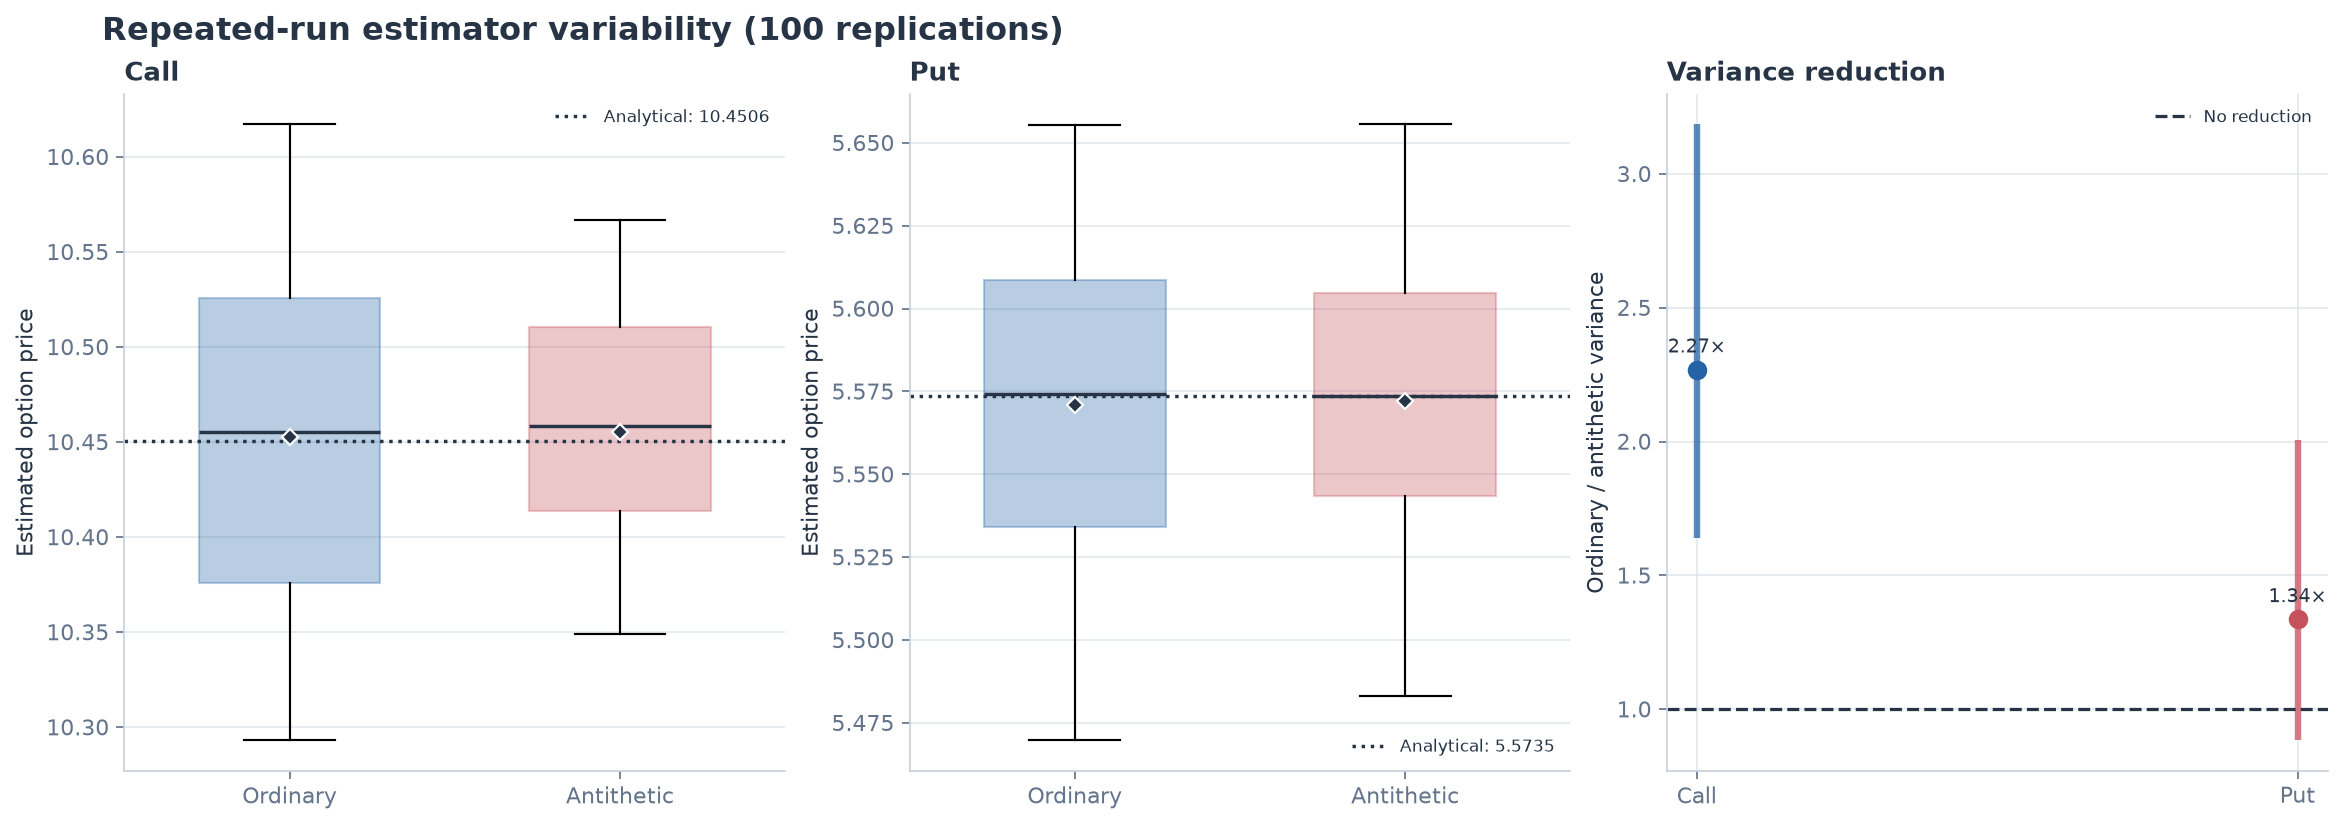

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5.2), constrained_layout=True)
for ax, kind in zip(axes[:2], option_types):
    data = [replicated_estimates[kind][method] for method in ('Ordinary', 'Antithetic')]
    boxes = ax.boxplot(
        data, positions=[0, 1], widths=0.55, patch_artist=True,
        showfliers=False, whis=(5, 95), showmeans=True,
        meanprops={'marker': 'D', 'markerfacecolor': INK,
                   'markeredgecolor': 'white', 'markersize': 5},
    )
    for patch, method in zip(boxes['boxes'], ('Ordinary', 'Antithetic')):
        patch.set_facecolor(METHOD_COLORS[method])
        patch.set_alpha(0.32)
        patch.set_edgecolor(METHOD_COLORS[method])
    for median in boxes['medians']:
        median.set_color(INK)
        median.set_linewidth(1.6)
    ax.axhline(analytical_prices[kind], color=INK, linestyle=':', linewidth=1.6,
               label=f'Analytical: {analytical_prices[kind]:.4f}')
    ax.set_xticks([0, 1], ['Ordinary', 'Antithetic'])
    ax.set_ylabel('Estimated option price')
    ax.set_title(kind.title(), loc='left')
    ax.grid(axis='x', visible=False)
    ax.legend(loc='best', fontsize=8)

ratio_ax = axes[2]
for x, kind in enumerate(option_types):
    ratio = variance_reduction[kind]
    low, high = bootstrap_intervals[kind]
    ratio_ax.vlines(x, low, high, color=COLORS[kind], linewidth=3, alpha=0.75)
    ratio_ax.scatter(x, ratio, color=COLORS[kind], s=65, zorder=3)
    ratio_ax.annotate(f'{ratio:.2f}×', (x, ratio), xytext=(0, 8),
                      textcoords='offset points', ha='center', fontsize=9, color=INK)
ratio_ax.axhline(1.0, color=INK, linestyle='--', linewidth=1.5, label='No reduction')
ratio_ax.set_xticks([0, 1], ['Call', 'Put'])
ratio_ax.set_ylabel('Ordinary / antithetic variance')
ratio_ax.set_title('Variance reduction', loc='left')
ratio_ax.legend(loc='best', fontsize=8)

fig.suptitle('Repeated-run estimator variability (100 replications)', x=0.04, ha='left')
plt.show()

## Numerical findings

The analytical values for the benchmark are approximately **10.4506** for the call and **5.5735** for the put. The analytical parity residual should be near floating-point roundoff, and both prices lie inside their respective discounted no-arbitrage bounds.

At 100,000 paths, the call estimates are 10.4083 (ordinary) and 10.4751 (antithetic); the put estimates are 5.5520 and 5.5784. All four 95% confidence intervals contain their analytical benchmark. In the 100-run experiment at 20,000 paths, the estimated variance ratio is 2.27× for calls (paired bootstrap 95% interval 1.64–3.19) and 1.34× for puts (0.88–2.01). The call interval supports a reduction in this experiment; the put interval includes 1, so the observed reduction is inconclusive at this level. The point estimates and distributions are sample-dependent and are not universal guarantees.

Confidence intervals use a normal approximation. The repeated-run experiment illustrates estimator variability for this benchmark rather than proving universal coverage or variance reduction.